## **California Traffic Collision Data from SWITRS: Data Extraction Using SQL and Visualization**

### **SWITRS Dataset**

The Statewide Integrated Traffic Records System (SWITRS) consists of data collected and maintained by the California Highway Patrol (CHP). SWITRS contains all crashes that were reported to CHP by local and governmental agencies.

The collection of traffic collision data helps law enforcement agencies to identify specific problems related to traffic safety and to seek effective solutions. (e.g. installing traffic lights or stop signs). 

> Source: https://studylib.net/doc/8190368/statewide-integrated-traffic-records-system

![https://mla5upscuucp.i.optimole.com/cb:0eB8.3ac01/w:auto/h:auto/q:mauto/https://esfandilawfirm.com/wp-content/uploads/impersonating-california-highway-patrol.jpg](https://mla5upscuucp.i.optimole.com/cb:0eB8.3ac01/w:auto/h:auto/q:mauto/https://esfandilawfirm.com/wp-content/uploads/impersonating-california-highway-patrol.jpg)

> Source: https://esfandilawfirm.com/crimes/vc-27-impersonating-a-chp-officer/

### **SQLite**

SQLite is a serverless, relational, lightweight database. It is stored in a single file. It does not support user management, nor is it designed for parallel use. It is ideal when we need a simple relational database. We can consider it an alternative for storing local data.

SQLite3 can be integrated into Python using the sqlite3 module, which was written by Gerhard Haring. It provides an SQL interface that complies with the DB-API 2.0 specification described in PEP 249. 

To use the sqlite3 module, you must first create a connection object representing the database, and then create a cursor object to help execute all SQL statements.


![https://www.sqlitetutorial.net/wp-content/uploads/2016/01/SQLite-Python.jpg](https://www.sqlitetutorial.net/wp-content/uploads/2016/01/SQLite-Python.jpg)

> Source: https://www.tutorialspoint.com/sqlite/sqlite_python.htm#

## **Let's start!**

One more short message at the beginning:

*Procuring raw data from the SWITRS database is tedious, so in this notebook I used a hosted dataset from Alex Gude. I encourage you to visit: https://alexgude.com/blog/switrs-sqlite-hosted-dataset/, where you can learn more about the data structure or linking methods. And the second point - this is not an exploratory data analysis. I focused more on the exercise of creating queries, and the visualization of some of the data allowed me to assess whether the results obtained are correct*.

In [1]:
# Import the necessary libraries
import plotly.express as px
import pandas as pd
import numpy as np
import sqlite3
import folium

In [2]:
# Declaration of colors and color palettes for visualization
plot_dictcolor = {'Property damage only': 'rgb(104,158,207)',
                  'Severe injury':        'rgb(245,87,91)',
                  'Other injury':         'rgb(245,162,87)',
                  'Fatal':                'rgb(161,161,161)',
                  'Pain':                 'rgb(245,214,87)'}

plot_bgcolor = 'rgb(249,249,249)'
plot_linecolor = 'rgb(120,161,120)'

---
### **Database connection**

In [3]:
# Connect to the database
cnx = sqlite3.connect('../datasets/switrs.sqlite') # https://www.kaggle.com/datasets/alexgude/california-traffic-collision-data-from-switrs

# Creation of an object (known as a cursor), which will make it possible to send queries to the database.
cursor = cnx.cursor()

In [4]:
# How many accidents were recorded?
df_total = pd.read_sql_query(
    """
    SELECT COUNT(case_id) AS Number_of_road_incidents
    FROM collisions;
    """, cnx)

df_total

,Number_of_road_incidents
0,9424334


---
### **Query the database and create data sets for visualization**

In [5]:
# How did the number of recorded traffic accidents break down over the years?
df_year_total = pd.read_sql_query(
    """
    SELECT STRFTIME('%Y', collision_date) AS Year, COUNT(case_id) AS Number_of_road_accidents
    FROM collisions
    GROUP BY Year;
    """, cnx)

In [6]:
# What was the percentage distribution of traffic accidents by severity?
df_severity = pd.read_sql_query(
    """
    SELECT collision_severity AS Severity, 
           ROUND((COUNT(case_id) * 100.0) / (SELECT COUNT(case_id) FROM collisions), 1) AS Percentage
    FROM collisions
    WHERE collision_severity <> 'N'
    GROUP BY Severity
    ORDER BY COUNT(case_id) DESC;
    """, cnx)

df_severity['Severity'] = df_severity['Severity'].str.capitalize()

In [7]:
# How many traffic accidents were there in each year by severity?
df_year_severity = pd.read_sql_query(
    """
    SELECT STRFTIME('%Y', collision_date) AS Year, 
           collision_severity AS Severity, COUNT(case_id) AS Number_of_road_incidents
    FROM collisions
    WHERE collision_severity <> 'N'
    GROUP BY Year, Severity;
    """, cnx)

df_year_severity['Severity'] = df_year_severity['Severity'].str.capitalize()

In [8]:
# How many traffic incidents were registered in each county?
df_county_total = pd.read_sql_query(
    """
    SELECT county_location AS County, COUNT(case_id) AS Number_of_road_incidents
    FROM collisions
    GROUP BY County
    ORDER BY Number_of_road_incidents DESC;
    """, cnx)

df_county_total['County'] = df_county_total['County'].str.title()

In [9]:
# What were the three most common causes of traffic accidents each year individually?
df_reason = pd.read_sql_query(
    """
    SELECT Year, Category, Percentage_of_annual_road_incidents 
    FROM (SELECT *, DENSE_RANK() OVER (PARTITION BY Year ORDER BY Percentage_of_annual_road_incidents DESC) AS Rank
          FROM (SELECT Tab2.Year, 
                       Tab2.Category, 
                       ROUND((Tab2.Subtotal * 100.0) / (Tab1.Annual_total_of_accidents), 1) AS Percentage_of_annual_road_incidents
                FROM (SELECT STRFTIME('%Y', collision_date) AS Year, pcf_violation_category AS Category, COUNT(case_id) 
                                                                                                         AS Subtotal
                      FROM collisions
                      GROUP BY Year, Category) AS Tab2 
                      JOIN (SELECT STRFTIME('%Y', collision_date) AS Year, COUNT(case_id) AS Annual_total_of_accidents
                            FROM collisions
                            GROUP BY Year) AS Tab1 ON Tab1.Year = Tab2.Year 
                GROUP BY Tab2.Year, Tab2.Category, Percentage_of_annual_road_incidents))
    WHERE Rank <= 3;
    """, cnx)

df_reason['Category'] = df_reason['Category'].str.capitalize()
df_reason['Category'] = df_reason['Category'].str.replace('Dui', 'DUI')

---
### **Data visualization**

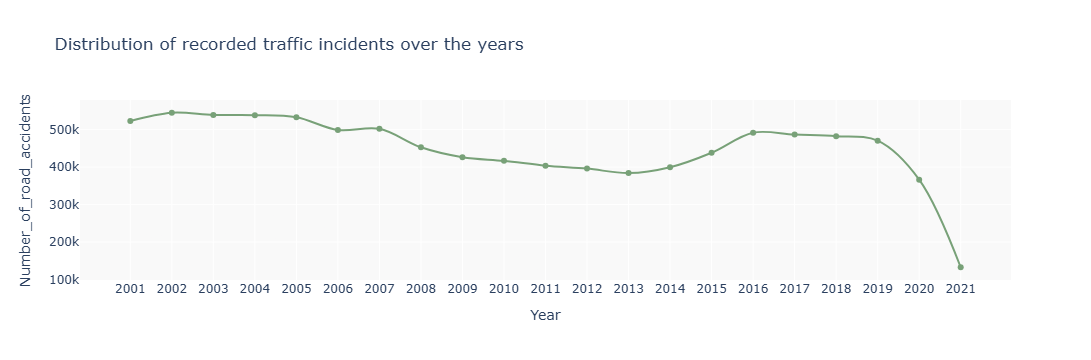

In [10]:
fig_year_total = px.line(
    df_year_total,
    x = 'Year',
    y = 'Number_of_road_accidents',
    line_shape = 'spline',
    markers = True,
    title = 'Distribution of recorded traffic incidents over the years')

fig_year_total.update_layout(plot_bgcolor = plot_bgcolor)
fig_year_total.update_traces(line_color = plot_linecolor)
fig_year_total.show()

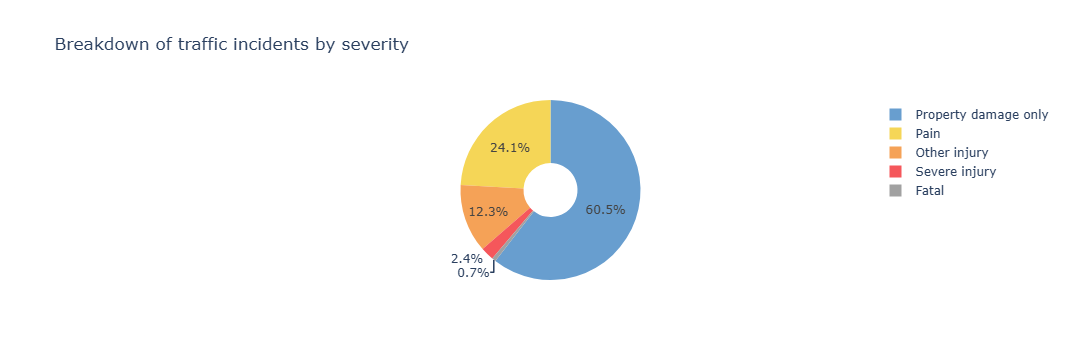

In [11]:
fig_severity = px.pie(
    df_severity, 
    values = 'Percentage', 
    names = 'Severity', 
    color = 'Severity',
    title = 'Breakdown of traffic incidents by severity',
    color_discrete_map = plot_dictcolor,
    hole = 0.3)

fig_severity.show()

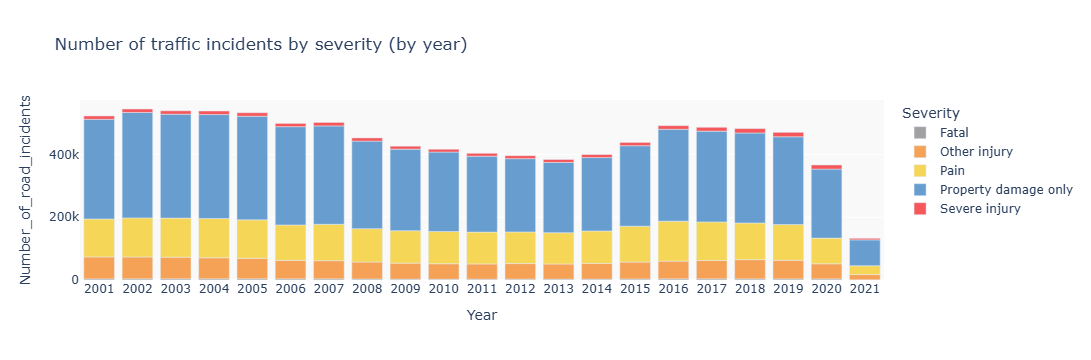

In [12]:
fig_year_severity = px.bar(
    df_year_severity, 
    x = 'Year', 
    y = 'Number_of_road_incidents', 
    color = 'Severity', 
    title = 'Number of traffic incidents by severity (by year)', 
    color_discrete_map = plot_dictcolor)

fig_year_severity.update_layout(plot_bgcolor = plot_bgcolor)
fig_year_severity.show()

In [13]:
dm_county_total = folium.Map(location = [33.4, -117.6], zoom_start = 6, width = 800, height = 550, tiles = 'cartodb positron')

folium.Choropleth(data = df_county_total,
    geo_data = '../datasets/california-counties.geojson',
    columns = ['County', 'Number_of_road_incidents'],
    legend_name = 'Accidents by county', 
    name = 'Accidents by county',
    key_on = 'feature.properties.name',
    fill_color = 'Greens',
    nan_fill_opacity = 0,
    fill_opacity = 0.7,
    line_opacity = 0.2,
    reset = True,
    bins = 12
    ).add_to(dm_county_total)

folium.LayerControl().add_to(dm_county_total)
dm_county_total

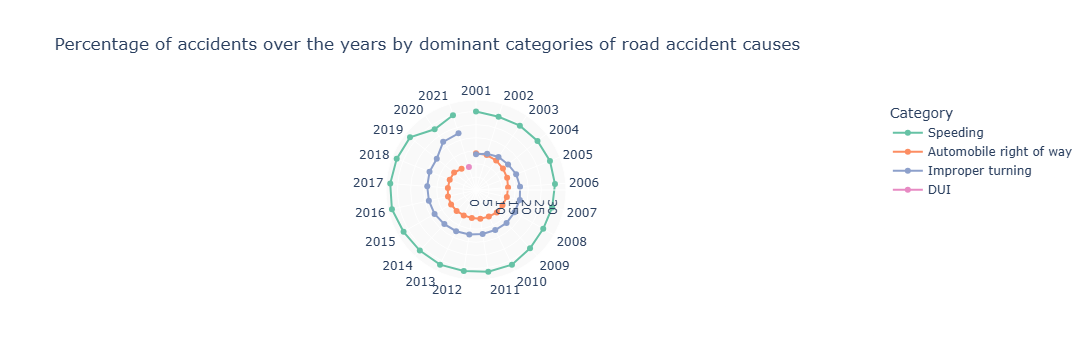

In [14]:
fig_reason = px.line_polar(
    df_reason,
    r = 'Percentage_of_annual_road_incidents',
    theta = 'Year',
    color = 'Category',
    title = 'Percentage of accidents over the years by dominant categories of road accident causes',
    color_discrete_sequence = px.colors.qualitative.Set2,
    markers = True)

fig_reason.update_layout(polar_bgcolor = plot_bgcolor)
fig_reason.show()

In [15]:
# Close the connection with the database
cnx.close()